In [1]:
import os, sys, time, pickle
import numpy as np
import torch
import matplotlib.pyplot as plt
from dataclasses import dataclass

from scipy.sparse.csgraph import connected_components
from scipy.stats import qmc
from sklearn.cluster import KMeans
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.ensemble import HistGradientBoostingRegressor

# make the repo root importable (train.py, agents/, utils/) when the kernel starts in experiments/
if os.path.abspath("..") not in sys.path:
    sys.path.insert(0, os.path.abspath(".."))

from cartpole_wind import cartpole_model_factory, make_envs  # also registers CartPoleWithWind-v1

## Load the trained RL2 policy and Set the experiments

In [17]:
CKPT = os.path.join("..", "checkpoints", "cartpole_wind.pt")

PARAM_BOUNDS = {"wind_mag": (-5.0, 5.0)}                                   # one parameter
# PARAM_BOUNDS = {"wind_mag": (-5.0, 5.0), "force_mag": (7.5, 12.5)}       # several parameters

N_TASKS = 40        # fitting tasks. One parameter: ~40 is plenty. Several: use more (e.g. 150-300)
N_TRIALS = 9        # trials per fitting task (multiple of N_FOLDS)
N_TEST_TASKS = 60   # random unseen tasks for the final test
TEST_TRIALS = 2
STEPS = 1024        # trial length (train.py horizon)
STRIDE = 4          # store every STRIDE-th step
T0 = 100            # ignore the first T0 steps of every trial when fitting and scoring
DIM = 4             # LDA dimensions
K_MAX = 10
N_FOLDS = 3
EXPLAINED = 0.95
SEED = 0

OUT = os.path.join("..", "hidden_clustering", "cartpole_wind_hidden_clustering_" + "_".join(PARAM_BOUNDS))
os.makedirs(OUT, exist_ok=True)

In [3]:
with open(CKPT, "rb") as f:
    if f.read(64).startswith(b"version https://git-lfs"):
        raise SystemExit(f"{CKPT} is a Git LFS pointer. Run `git lfs pull` in your clone first.")

model = cartpole_model_factory()
ckpt = torch.load(CKPT, map_location="cpu")
model.load_state_dict(ckpt["model_state_dict"] if isinstance(ckpt, dict) and "model_state_dict" in ckpt else ckpt)
model.eval();

## Tasks and Data
```make_task_set``` gives an even grid for one task parameter and a Halton sequence for several task parameters. Parameters are rescaled to [0, 1] (```theta_u```) so that distances in the task graph are comparable across parameters

In [4]:
def make_task_set(bounds, n, seed=0):
    """Draw task-parameter vectors that cover a box evenly.

    One parameter: an evenly spaced grid, end points included.  Several parameters: a scrambled
    Halton sequence (even coverage for any number of points).

    Parameters
    ----------
    bounds : dict[str, tuple[float, float]]
        {parameter name: (low, high)}, d entries.  The names must be keyword arguments of the
        environment.
    n : int
        Number of tasks K to generate.
    seed : int, default 0
        Seed of the scrambled Halton sequence (ignored when d == 1).

    Returns
    -------
    keys : list[str], length d
        Parameter names, in the order of the columns of `theta`.
    theta : ndarray, shape (n, d)
        One task per row, in the original units (low <= value <= high).
    """
    keys = list(bounds)
    lo = np.array([bounds[k][0] for k in keys], dtype=float)
    hi = np.array([bounds[k][1] for k in keys], dtype=float)
    if len(keys) == 1:
        u = np.linspace(0.0, 1.0, n)[:, None]
    else:
        u = qmc.Halton(d=len(keys), scramble=True, seed=seed).random(n)
    return keys, lo + u * (hi - lo)


def to_unit(theta, bounds):
    """Scale task parameters to [0, 1] per parameter, so that distances are comparable.

    Parameters
    ----------
    theta : array_like, shape (d,) or (M, d)
        Parameter vector(s) in the original units.
    bounds : dict[str, tuple[float, float]]
        {parameter name: (low, high)}, d entries, in the same order as the columns of `theta`.

    Returns
    -------
    ndarray, same shape as `theta`
        (theta - low) / (high - low), column by column.
    """
    lo = np.array([b[0] for b in bounds.values()], dtype=float)
    hi = np.array([b[1] for b in bounds.values()], dtype=float)
    return (np.asarray(theta, dtype=float) - lo) / (hi - lo)


def task_graph(theta_u, n_neighbors=None):
    """Boolean adjacency matrix of tasks that are neighbours in parameter space.

    One parameter: a chain of the tasks sorted by their value.  Several parameters: a symmetrised
    k-nearest-neighbour graph, with the number of neighbours raised until the graph is connected.

    Parameters
    ----------
    theta_u : ndarray, shape (K, d)
        Task parameters scaled to [0, 1] (see `to_unit`).
    n_neighbors : int or None, default None
        Starting number of neighbours per task when d > 1 (None -> 2 * d + 2).  Ignored if d == 1.

    Returns
    -------
    adj : ndarray of bool, shape (K, K)
        Symmetric; adj[i, j] is True if tasks i and j are neighbours.  The diagonal is False.
    """
    K, d = theta_u.shape
    adj = np.zeros((K, K), dtype=bool)
    if d == 1:
        o = np.argsort(theta_u[:, 0])
        adj[o[:-1], o[1:]] = True
        return adj | adj.T
    D = ((theta_u[:, None] - theta_u[None]) ** 2).sum(-1)
    np.fill_diagonal(D, np.inf)
    order = np.argsort(D, axis=1)
    k = n_neighbors or 2 * d + 2
    while True:
        adj[:] = False
        rows = np.repeat(np.arange(K), k)
        adj[rows, order[:, :k].ravel()] = True
        adj |= adj.T
        if connected_components(adj, directed=False)[0] == 1 or k >= K - 1:
            return adj
        k += 1

In [5]:
keys, theta = make_task_set(PARAM_BOUNDS, N_TASKS, seed=SEED)       # (N_TASKS, d)
theta_u = to_unit(theta, PARAM_BOUNDS)
adj = task_graph(theta_u)
tasks = [dict(zip(keys, map(float, th))) for th in theta]

lo = np.array([b[0] for b in PARAM_BOUNDS.values()]); hi = np.array([b[1] for b in PARAM_BOUNDS.values()])
test_theta = np.random.default_rng(SEED + 123).uniform(lo, hi, (N_TEST_TASKS, len(keys)))
test_tasks = [dict(zip(keys, map(float, th))) for th in test_theta]

print(f"{len(keys)} parameter(s) {keys}; {adj.sum() // 2} edges in the task graph ({adj.sum() / len(adj):.1f} neighbours per task)")

1 parameter(s) ['wind_mag']; 39 edges in the task graph (1.9 neighbours per task)


## Collection of Hidden States

In [6]:
@torch.no_grad()
def collect(model, make_envs, tasks, n_trials, steps=1024, stride=4, deterministic=True, seed=0):
    """Roll out `n_trials` independent trials for every task and store the GRU hidden states.

    Follows the training protocol: `h` starts as None at step 0 of every trial, the previous
    action / reward are 0 and prev_done is 1 at t = 0.  `h` is NOT reset at episode boundaries.
    All K * n_trials trials run in parallel as one vectorised environment (task-major order:
    the trials of task 0 first, then the trials of task 1, ...).

    Parameters
    ----------
    model : torch.nn.Module
        RL2 policy.  Called as
        `logits, value, h = model(obs, prev_a, prev_r, prev_done, h)` with obs (1, n_env, obs_dim),
        prev_a (1, n_env), prev_r (1, n_env, 1), prev_done (1, n_env, 1) and h (1, n_env, H) or
        None; `logits` has shape (1, n_env, n_actions).
    make_envs : callable
        `make_envs(list_of_kwargs_dicts)` -> vectorised env of n_env = K * n_trials copies, each built
        with its own dict of environment keyword arguments.  Observations have shape (n_env, obs_dim).
    tasks : list[dict], length K
        One dict of environment keyword arguments per task, e.g. {"wind_mag": 1.3}.
    n_trials : int
        Independent trials per task.
    steps : int, default 1024
        Length T of a trial in environment steps (several episodes follow each other inside a trial).
    stride : int, default 4
        Store every `stride`-th step, i.e. S = ceil(steps / stride) stored steps per trial, since ht+1 is highly correlated with ht
    deterministic : bool, default True
        Greedy actions (argmax of the logits) if True, sampled actions otherwise.
    seed : int, default 0
        Seed for the environment reset and for torch.

    Returns
    -------
    dict of ndarray
        N = K * n_trials * S rows, ordered trial by trial and, within a trial, by step.
            "h"         (N, H)        float32  hidden state after the model processed step t
            "task_idx"  (N,)          int      task index in 0 .. K-1
            "trial"     (N,)          int      trial index in 0 .. n_trials-1
            "t"         (N,)          int      step inside the trial (0, stride, 2 * stride, ...)
            "obs"       (N, obs_dim)  float32  observation at step t
            "dobs"      (N, obs_dim)  float32  obs[t] - obs[t-1] (0 at t = 0)
            "prev_a"    (N,)          int64    action taken at step t-1 (0 at t = 0)
            "prev_done" (N,)          float32  1.0 at t = 0 and on the step right after an episode
                                               ended (the "dummy" step), else 0.0
    """

    
    model.eval()
    K = len(tasks)
    n_env = K * n_trials
    envs = make_envs([dict(tk) for tk in tasks for _ in range(n_trials)])

    torch.manual_seed(seed)
    obs, _ = envs.reset(seed=seed)

    h = None
    prev_a = np.zeros(n_env, dtype=np.int64)
    prev_r = np.zeros(n_env, dtype=np.float32)
    prev_done = np.ones(n_env, dtype=np.float32) # start of an episode
    prev_obs = obs.copy()

    store_steps = list(range(0, steps, stride))
    h_dim = model.h_dim
    H = np.zeros((n_env, len(store_steps), h_dim), dtype=np.float32)
    OBS = np.zeros((n_env, len(store_steps), obs.shape[-1]), dtype=np.float32)
    DOBS = np.zeros_like(OBS)
    PA = np.zeros((n_env, len(store_steps)), dtype=np.int64)
    PD = np.zeros((n_env, len(store_steps)), dtype=np.float32)

    j = 0
    for t in range(steps):
        o = torch.as_tensor(obs, dtype=torch.float32).unsqueeze(0)
        pa = torch.as_tensor(prev_a).unsqueeze(0)
        pr = torch.as_tensor(prev_r).view(1, n_env, 1)
        pd = torch.as_tensor(prev_done).view(1, n_env, 1)

        logits, _, h = model(o, pa, pr, pd, h)
        logits = logits.squeeze(0)
        act = logits.argmax(-1) if deterministic else torch.distributions.Categorical(logits=logits).sample()
        act = act.cpu().numpy()

        if t % stride == 0:
            H[:, j] = h.squeeze(0).cpu().numpy()
            OBS[:, j] = obs
            DOBS[:, j] = obs - prev_obs
            PA[:, j] = prev_a
            PD[:, j] = prev_done
            j += 1

        prev_obs = obs
        obs, rew, term, trunc, _ = envs.step(act)
        done = np.logical_or(term, trunc).astype(np.float32)
        prev_a, prev_r, prev_done = act.astype(np.int64), np.asarray(rew, dtype=np.float32), done
    envs.close()

    S = len(store_steps)
    rep = lambda x: np.repeat(x, S)
    return {
        "h": H.reshape(-1, h_dim),
        "task_idx": rep(np.repeat(np.arange(K), n_trials)),
        "trial": rep(np.tile(np.arange(n_trials), K)),
        "t": np.tile(np.asarray(store_steps), n_env),
        "obs": OBS.reshape(-1, OBS.shape[-1]),
        "dobs": DOBS.reshape(-1, DOBS.shape[-1]),
        "prev_a": PA.reshape(-1),
        "prev_done": PD.reshape(-1),
    }


def select(data, mask):
    """Keep only the rows of every array in `data` where `mask` is True.

    Parameters
    ----------
    data : dict[str, ndarray]
        Arrays that all have N rows along axis 0 (as returned by `collect`).
    mask : ndarray of bool, shape (N,)
        Rows to keep.

    Returns
    -------
    dict[str, ndarray]
        Same keys; every array has M = mask.sum() rows.
    """
    return {k: v[mask] for k, v in data.items()}

In [7]:
def collect_or_load(name, task_list, n_trials, seed):
    '''Run `collect` once and cache the result as OUT/dataset_<name>.npz.

    The cache is keyed only by `name`: delete the file after you change the tasks, STEPS,
    STRIDE or the model.

    Parameters
    ----------
    name : str
        "dev" (fitting tasks) or "test" (unseen tasks); part of the cache file name.
    task_list : list[dict], length K
        One dict of environment keyword arguments per task.
    n_trials : int
        Independent trials per task.
    seed : int
        Seed passed to `collect`.

    Returns
    -------
    dict[str, ndarray]
        Same arrays as `collect` (N rows each).
    '''
    path =os.path.join(OUT, f"dataset_{name}.npz")
    if os.path.exists(path):
        with np.load(path) as f:
            return {k: f[k] for k in f.files}
    data = collect(model, make_envs, task_list, n_trials, STEPS, STRIDE, seed=seed)
    np.savez_compressed(path, **data)
    return data

t_start = time.time()
dev = collect_or_load("dev", tasks, N_TRIALS, SEED)                      # fitting tasks
test = collect_or_load("test", test_tasks, TEST_TRIALS, SEED + 10_000)   # unseen tasks
print({k: v.shape for k, v in dev.items()}, f"[{time.time() - t_start:.0f}s]")

{'h': (92160, 64), 'task_idx': (92160,), 'trial': (92160,), 't': (92160,), 'obs': (92160, 4), 'dobs': (92160, 4), 'prev_a': (92160,), 'prev_done': (92160,)} [0s]


In [8]:
d_fit = select(dev, (dev["t"] >= T0) & (dev["prev_done"] == 0)) # drop dummy steps 
test = select(test, test["prev_done"] == 0)
len(d_fit["h"]), len(test["h"])

(82800, 30480)

## Projection
LDA & whitening on the task labels

In [9]:
@dataclass
class Projector:
    """Affine map from hidden states to the whitened LDA space: z = (x - xbar) @ A.

    Attributes
    ----------
    xbar : ndarray, shape (H,)
        Mean of the hidden states the projector was fitted on.
    A : ndarray, shape (H, D)
        LDA directions followed by whitening (A = B @ Sigma^(-1/2)).  D = number of LDA directions.
    """
    xbar: np.ndarray
    A: np.ndarray

    def __call__(self, X):
        """Project hidden states.

        Parameters
        ----------
        X : array_like, shape (N, H) or (H,)
            Hidden state(s).

        Returns
        -------
        ndarray, shape (N, D) or (D,)
            Whitened coordinates, float64.
        """
        return (np.asarray(X, dtype=np.float64) - self.xbar) @ self.A


def fit_projector(X, task_idx, dim=4):
    """LDA on the task labels, then whiten with the pooled within-task covariance.

    Parameters
    ----------
    X : array_like, shape (N, H)
        Hidden states.
    task_idx : ndarray of int, shape (N,)
        Task index (0 .. K-1) of every row; used as the class label for LDA.
    dim : int, default 4
        Number of LDA directions to keep.  The result has D = min(dim, H, K - 1) directions, because
        LDA has at most K - 1 useful directions.

    Returns
    -------
    Projector
        With xbar of shape (H,) and A of shape (H, D).
    """
    X = np.asarray(X, dtype=np.float64)
    lda = LinearDiscriminantAnalysis(solver="eigen", shrinkage="auto").fit(X, task_idx)
    dim = int(min(dim, lda.scalings_.shape[1], len(np.unique(task_idx)) - 1))
    B = lda.scalings_[:, :dim]
    xbar = X.mean(0)
    Z = (X - xbar) @ B

    K = int(task_idx.max()) + 1
    cnt = np.bincount(task_idx, minlength=K).astype(float)
    mu = np.zeros((K, dim))
    np.add.at(mu, task_idx, Z)
    mu /= np.maximum(cnt, 1)[:, None]
    Zc = Z - mu[task_idx]
    W = Zc.T @ Zc / len(Zc)
    evals, evecs = np.linalg.eigh(W)
    Wih = evecs @ np.diag(1.0 / np.sqrt(np.maximum(evals, 1e-12))) @ evecs.T
    return Projector(xbar=xbar, A=B @ Wih)

## Clustering the tasks
* `constrained_ward`: the **build** step. Merge only clusters that are adjacent in the task graph. Return the labelling for every `k` on the way down to 1.
* `refine`: the **refine** step. Moves a border task to a neighbouring cluster if that lowers the error and the cluster it leaves stays connected.

In [10]:
def task_stats(Z, task_idx, K):
    """Per-task sufficient statistics of the projected hidden states.

    Parameters
    ----------
    Z : ndarray, shape (N, D)
        Projected (whitened) hidden states.
    task_idx : ndarray of int, shape (N,)
        Task index (0 .. K-1) of every row.
    K : int
        Number of tasks.

    Returns
    -------
    n : ndarray, shape (K,)
        Number of rows of each task.
    s : ndarray, shape (K, D)
        Sum of the rows of each task.
    q : ndarray, shape (K,)
        Sum of the squared norms |z|^2 of the rows of each task.
    """
    n = np.bincount(task_idx, minlength=K).astype(float)
    s = np.zeros((K, Z.shape[1]))
    np.add.at(s, task_idx, Z)
    q = np.bincount(task_idx, weights=(Z ** 2).sum(1), minlength=K)
    return n, s, q



def cluster_sse(labels, n, s, q):
    """Total within-cluster squared error of a clustering of the tasks.

    For a cluster c the error is sum(q) - |sum(s)|^2 / sum(n) over its tasks, i.e. the squared
    distance of all its rows to the cluster mean.

    Parameters
    ----------
    labels : ndarray of int, shape (K,)
        Cluster index (0 .. k-1) of every task.
    n : ndarray, shape (K,)
        Rows per task (see `task_stats`).
    s : ndarray, shape (K, D)
        Sum of the rows per task.
    q : ndarray, shape (K,)
        Sum of squared norms per task.

    Returns
    -------
    float
        Sum of the errors of all clusters.
    """
    k = labels.max() + 1
    N = np.bincount(labels, weights=n, minlength=k)
    Q = np.bincount(labels, weights=q, minlength=k)
    S = np.zeros((k, s.shape[1]))
    np.add.at(S, labels, s)
    return float((Q - (S ** 2).sum(1) / np.maximum(N, 1e-12)).sum())


def _relabel(labels, theta_u):
    """Number the clusters by the position of their tasks along the first parameter.

    Parameters
    ----------
    labels : ndarray of int, shape (K,)
        Cluster ids (any integers, not necessarily consecutive).
    theta_u : ndarray, shape (K, d)
        Task parameters scaled to [0, 1]; only column 0 is used.

    Returns
    -------
    ndarray of int, shape (K,)
        Ids 0 .. k-1, increasing with the mean value of the first parameter of the cluster's tasks.
    """
    ids = np.unique(labels)
    pos = [theta_u[labels == i, 0].mean() for i in ids]
    new = np.empty_like(labels)
    for r, i in enumerate(np.argsort(pos)):
        new[labels == ids[i]] = r
    return new



def constrained_ward(n, s, adj, k_max):
    """Agglomerative clustering of the tasks (Ward criterion) that may only merge clusters that touch
    in the task graph.

    Starts with one cluster per task and repeatedly merges the two touching clusters whose merge
    increases the squared error least.

    Parameters
    ----------
    n : ndarray, shape (K,)
        number of examples (hidden states) per task (see `task_stats`).
    s : ndarray, shape (K, D)
        Sum of the rows per task.
    adj : ndarray of bool, shape (K, K)
        Task graph (see `task_graph`); must be connected.
    k_max : int
        Largest number of clusters to return.

    Returns
    -------
    dict[int, ndarray]
        {k: labels} for k = min(k_max, K), ..., 1; labels has shape (K,) with ids 0 .. k-1.

    Raises
    ------
    ValueError
        If the task graph is not connected.
    """
    K = len(n)
    cnt, sm = n.copy(), s.copy()
    A = adj.copy()
    np.fill_diagonal(A, False)
    alive = np.ones(K, dtype=bool) # if this cluster exists 
    labels = np.arange(K)
    out = {}
    if K <= k_max:
        out[K] = labels.copy()
    for m in range(K, 1, -1):  # m clusters alive -> m - 1
        mean = sm / np.maximum(cnt, 1e-12)[:, None] # cluster means [K, D]
        d2 = ((mean[:, None] - mean[None]) ** 2).sum(-1) # distances between each pair of cluster mean [K, K]
        cost = d2 * (cnt[:, None] * cnt[None] / np.maximum(cnt[:, None] + cnt[None], 1e-12)) # compute pairwise cost
        cost[~(A & alive[:, None] & alive[None])] = np.inf
        a, b = np.unravel_index(np.argmin(cost), cost.shape) # pick the pair with lowest merge cost 
        if not np.isfinite(cost[a, b]):
            raise ValueError("task graph is not connected")
        cnt[a] += cnt[b] # merge b into a: counts are added 
        sm[a] += sm[b] # sums are added
        A[a] |= A[b] # a inherits all of b's neighbourhoods
        A[:, a] |= A[:, b] # a inherits all of b's neighbourhoods
        A[a, a] = False  #
        alive[b] = False
        A[b] = False
        A[:, b] = False
        labels[labels == b] = a # Every cluster labelled b is relabelled a
        if m - 1 <= k_max:
            out[m - 1] = labels.copy()
    return {k: np.unique(v, return_inverse=True)[1] for k, v in out.items()}



def refine(labels, n, s, q, adj, max_sweeps=50):
    """Local search: move a task on a cluster border to the neighbouring cluster if that lowers the
    squared error and keeps the cluster it leaves connected.  Repeats until nothing moves.

    Parameters
    ----------
    labels : ndarray of int, shape (K,)
        Starting clustering (ids 0 .. k-1).  Not modified.
    n : ndarray, shape (K,)
        Rows per task.
    s : ndarray, shape (K, D)
        Sum of the rows per task.
    q : ndarray, shape (K,)
        Sum of squared norms per task.  Not used here (its total cancels when two clusterings are
        compared); kept so that the signature matches `cluster_sse`.
    adj : ndarray of bool, shape (K, K)
        Task graph.
    max_sweeps : int, default 50
        Maximum number of passes over all tasks.

    Returns
    -------
    ndarray of int, shape (K,)
        Refined labels (a copy), same number of clusters.
    """
    labels = labels.copy()
    k = labels.max() + 1
    N = np.bincount(labels, weights=n, minlength=k)
    S = np.zeros((k, s.shape[1]))
    np.add.at(S, labels, s)
    def sse(Ncl, Scl):
        """Squared error of one cluster up to the constant sum(q): -|sum(s)|^2 / sum(n).

        Parameters
        ----------
        Ncl : float
            Number of rows in the cluster.
        Scl : ndarray, shape (D,)
            Sum of the rows in the cluster.

        Returns
        -------
        float
        """
        return -(Scl ** 2).sum() / max(Ncl, 1e-12)  # the constant sum(q) cancels in deltas

    def stays_connected(members):
        """Whether the given tasks form one connected piece of the task graph.

        Parameters
        ----------
        members : ndarray of int, shape (m,)
            Task indices.

        Returns
        -------
        bool
            True if m <= 1 or the subgraph of `adj` on `members` is connected.
        """
        if len(members) <= 1:
            return True
        return connected_components(adj[np.ix_(members, members)], directed=False)[0] == 1

    for _ in range(max_sweeps):
        moved = False
        for i in range(len(labels)):
            a = labels[i]
            if (labels == a).sum() == 1:
                continue
            best_b, best_gain = None, -1e-9
            for b in np.unique(labels[adj[i]]):
                if b == a:
                    continue
                before = sse(N[a], S[a]) + sse(N[b], S[b])
                after = sse(N[a] - n[i], S[a] - s[i]) + sse(N[b] + n[i], S[b] + s[i])
                if after - before < best_gain:
                    best_b, best_gain = b, after - before
            if best_b is None:
                continue
            rest = np.where((labels == a) & (np.arange(len(labels)) != i))[0]
            if not stays_connected(rest):
                continue
            N[a] -= n[i]; S[a] -= s[i]; N[best_b] += n[i]; S[best_b] += s[i]
            labels[i] = best_b
            moved = True
        if not moved:
            break
    return labels

In [11]:
def cluster_tasks(n, s, q, adj, k_max, theta_u, do_refine=True):
    """Cluster the tasks for every k: build with constrained Ward, then refine each k.

    Parameters
    ----------
    n : ndarray, shape (K,)
        Rows per task (see `task_stats`).
    s : ndarray, shape (K, D)
        Sum of the rows per task.
    q : ndarray, shape (K,)
        Sum of squared norms per task.
    adj : ndarray of bool, shape (K, K)
        Task graph.
    k_max : int
        Largest number of clusters.
    theta_u : ndarray, shape (K, d)
        Task parameters scaled to [0, 1]; only used to number the clusters.
    do_refine : bool, default True
        Apply `refine` after the Ward build.

    Returns
    -------
    dict[int, ndarray]
        {k: labels} for k = min(k_max, K), ..., 1; labels has shape (K,), ids 0 .. k-1 ordered by
        position along the first parameter.
    """
    parts = constrained_ward(n, s, adj, k_max)
    if do_refine:
        parts = {k: refine(v, n, s, q, adj) for k, v in parts.items()}
    return {k: _relabel(v, theta_u) for k, v in parts.items()}


def heldout_sse(Z, task_idx, labels, means):
    """Mean squared distance of held-out samples to the mean of their task's cluster.

    Parameters
    ----------
    Z : ndarray, shape (M, D)
        Held-out projected (whitened) hidden states.
    task_idx : ndarray of int, shape (M,)
        Task index (0 .. K-1) of every row.
    labels : ndarray of int, shape (K,)
        Cluster of every task.
    means : ndarray, shape (k, D)
        Cluster means (see `cluster_means`).

    Returns
    -------
    float
        Average over the M rows of |z - means[labels[task]]|^2.  About D if the model is perfect.
    """
    return float(((Z - means[labels[task_idx]]) ** 2).sum(1).mean())


def cluster_means(labels, n, s):
    """Mean of the projected hidden states of every cluster.

    Parameters
    ----------
    labels : ndarray of int, shape (K,)
        Cluster of every task (ids 0 .. k-1).
    n : ndarray, shape (K,)
        Rows per task.
    s : ndarray, shape (K, D)
        Sum of the rows per task.

    Returns
    -------
    ndarray, shape (k, D)
        Sum of s over the cluster's tasks divided by the sum of n.
    """
    k = labels.max() + 1
    cnt = np.bincount(labels, weights=n, minlength=k)
    sm = np.zeros((k, s.shape[1]))
    np.add.at(sm, labels, s)
    return sm / cnt[:, None]

## Selecting K based on Cross Validation
Trial-wise cross-validation: fit projector, clusters and means on the other trials, score on the held-out ones (mean squared distance in whitened space; the floor is about `DIM`). The chosen `k` is the smallest whose held-out score is within `1 - EXPLAINED` of the total gain. The reference curve is k-means on the task means with **no** neighbour constraint, i.e. what the constraint costs.

In [12]:
def cv_select(X, task_idx, trial, K, adj, theta_u, dim=4, k_max=10, n_folds=3, explained=0.95):
    """Choose the number of clusters with trial-wise cross-validation.

    Fold f holds out the trials with `trial % n_folds == f`.  For each fold the projector, the
    clusters and their means are fitted on the other trials and scored on the held-out ones
    (`heldout_sse`).  The chosen k is the smallest whose mean held-out score is within
    (1 - explained) of the total gain from k = 1 to the best k.  The reference curve is k-means on
    the task means with NO neighbour constraint, i.e. what the constraint costs.

    Parameters
    ----------
    X : ndarray, shape (N, H)
        Hidden states (rows to fit on).
    task_idx : ndarray of int, shape (N,)
        Task index (0 .. K-1) of every row.
    trial : ndarray of int, shape (N,)
        Trial index of every row, used to build the folds.
    K : int
        Number of tasks.
    adj : ndarray of bool, shape (K, K)
        Task graph.
    theta_u : ndarray, shape (K, d)
        Task parameters scaled to [0, 1].
    dim : int, default 4
        Number of LDA directions.
    k_max : int, default 10
        Largest number of clusters tried (capped at K).
    n_folds : int, default 3
        Number of cross-validation folds.
    explained : float, default 0.95
        Fraction of the total gain the chosen k must reach.

    Returns
    -------
    dict
        "k"        int                chosen number of clusters
        "ks"       (k_max,)           1, 2, ..., k_max (k_max capped at K)
        "opt_mean" (k_max,)           held-out score of the constrained clusters, mean over folds
        "opt_std"  (k_max,)           ... standard deviation over folds
        "ref_mean" (k_max,)           held-out score of the unconstrained k-means reference
        "ref_std"  (k_max,)           ... standard deviation over folds
    """
    k_max = min(k_max, K)
    folds = trial % n_folds
    opt = np.zeros((n_folds, k_max)) # constrained score 
    ref = np.zeros((n_folds, k_max)) # reference score
    for f in range(n_folds):
        tr, va = folds != f, folds == f
        proj = fit_projector(X[tr], task_idx[tr], dim)
        Ztr, Zva = proj(X[tr]), proj(X[va])
        n, s, q = task_stats(Ztr, task_idx[tr], K)
        parts = cluster_tasks(n, s, q, adj, k_max, theta_u)
        task_mean = s / n[:, None]
        for k in range(1, k_max + 1):
            lab = parts[k]
            opt[f, k - 1] = heldout_sse(Zva, task_idx[va], lab, cluster_means(lab, n, s))
            km = KMeans(k, n_init=5, random_state=0).fit(task_mean, sample_weight=n)
            ref[f, k - 1] = heldout_sse(Zva, task_idx[va], km.labels_, cluster_means(km.labels_, n, s))

    mean = opt.mean(0)
    floor = mean.min()
    total = mean[0] - floor
    if total <= 1e-9:
        k_star = 1
    else:
        k_star = int(np.where(mean - floor <= (1.0 - explained) * total)[0][0]) + 1
    return {"k": k_star, "ks": np.arange(1, k_max + 1), "opt_mean": mean, "opt_std": opt.std(0),
            "ref_mean": ref.mean(0), "ref_std": ref.std(0)}

In [13]:
cv = cv_select(d_fit["h"], d_fit["task_idx"], d_fit["trial"], N_TASKS, adj, theta_u, dim=DIM,
               k_max=K_MAX, n_folds=N_FOLDS, explained=EXPLAINED)
print("held-out score per k:", ", ".join(f"{k}:{v:.2f}" for k, v in zip(cv["ks"], cv["opt_mean"])))
print("chosen k =", cv["k"])

held-out score per k: 1:275.33, 2:80.96, 3:38.71, 4:24.66, 5:17.93, 6:13.31, 7:11.09, 8:9.89, 9:9.26, 10:8.30
chosen k = 5


## Deplyable Model
Projector + cluster means + the cluster of every fitted task. A new hidden state gets the cluster of its nearest fitted task. Gives hard assignments, posteriors and an out-of-distribution score.

In [14]:
@dataclass
class ClusterModel:
    """Deployable model: projector + cluster means + the cluster of every fitted task.

    Attributes
    ----------
    projector : Projector
        Maps hidden states (H,) to whitened coordinates (D,).
    means : ndarray, shape (k, D)
        Cluster means in the whitened space.
    task_labels : ndarray of int, shape (K,)
        Cluster (0 .. k-1) of every fitted task.
    theta_u : ndarray, shape (K, d)
        Fitted tasks, parameters scaled to [0, 1].
    bounds : dict[str, tuple[float, float]]
        {parameter name: (low, high)}, d entries.
    cluster_adj : ndarray of bool, shape (k, k)
        cluster_adj[a, b] is True if some task of cluster a is a neighbour of some task of cluster b.
    """
    projector: Projector
    means: np.ndarray        # (k, dim) cluster means in whitened space
    task_labels: np.ndarray  # (K,) cluster of every fitted task
    theta_u: np.ndarray      # (K, d) fitted tasks, scaled to [0, 1]
    bounds: dict             # {parameter name: (lo, hi)}
    cluster_adj: np.ndarray  # (k, k) clusters that touch each other

    @property
    def k(self):
        """Number of clusters (int)."""
        return len(self.means)

    def cluster_of_theta(self, theta):
        """Cluster of task-parameter vector(s): the cluster of the nearest fitted task.

        Parameters
        ----------
        theta : array_like, shape (d,) or (M, d)
            Parameters in the original units.

        Returns
        -------
        ndarray of int, shape (M,)
            Cluster index of every vector (M = 1 for a single vector of shape (d,)).
        """
        u = to_unit(np.atleast_2d(theta), self.bounds)
        d2 = ((u[:, None] - self.theta_u[None]) ** 2).sum(-1)
        return self.task_labels[d2.argmin(1)]

    def project(self, h):
        """Project hidden states into the whitened LDA space.

        Parameters
        ----------
        h : array_like, shape (N, H) or (H,)
            Hidden state(s).

        Returns
        -------
        ndarray, shape (N, D) or (D,)
        """
        return self.projector(h)

    def sqdist_from_z(self, Z):
        """Squared Euclidean distance of projected states to every cluster mean.

        Parameters
        ----------
        Z : ndarray, shape (N, D)
            Projected states (2-D; use Z[None] for a single state).

        Returns
        -------
        ndarray, shape (N, k)
            d2[i, c] = |Z[i] - means[c]|^2.
        """
        return ((Z[:, None, :] - self.means[None]) ** 2).sum(-1)

    def predict_from_z(self, Z):
        """Nearest cluster mean for already projected states.

        Parameters
        ----------
        Z : ndarray, shape (N, D)
            Projected states.

        Returns
        -------
        ndarray of int, shape (N,)
            Index of the nearest cluster mean.
        """
        return self.sqdist_from_z(Z).argmin(1)

    def predict(self, h):
        """Assign hidden states to clusters (hard assignment).

        Parameters
        ----------
        h : ndarray, shape (N, H)
            Hidden states (2-D; use h[None] for a single state).

        Returns
        -------
        ndarray of int, shape (N,)
            Index (0 .. k-1) of the nearest cluster mean in the whitened space.
        """
        return self.predict_from_z(self.project(h))

    def predict_proba(self, h):
        """Soft assignment: posterior over clusters under unit-variance Gaussians with equal priors.

        Parameters
        ----------
        h : ndarray, shape (N, H)
            Hidden states (2-D).

        Returns
        -------
        ndarray, shape (N, k)
            softmax(-0.5 * squared distance) over the clusters; every row sums to 1.
        """
        d2 = self.sqdist_from_z(self.project(h))
        p = np.exp(-0.5 * (d2 - d2.min(1, keepdims=True)))
        return p / p.sum(1, keepdims=True)

    def ood_score(self, h):
        """Out-of-distribution score: squared distance to the nearest cluster mean.

        Roughly chi-square distributed with D degrees of freedom for states from the fitted tasks, so
        values far above D indicate a hidden state that none of the clusters explains.

        Parameters
        ----------
        h : ndarray, shape (N, H)
            Hidden states (2-D).

        Returns
        -------
        ndarray, shape (N,)
        """
        return self.sqdist_from_z(self.project(h)).min(1)

    def save(self, path):
        """Pickle the model.

        Parameters
        ----------
        path : str
            Output file.
        """
        with open(path, "wb") as f:
            pickle.dump(self, f)

    @staticmethod
    def load(path):
        """Load a model written by `save`.

        Parameters
        ----------
        path : str
            Pickle file.

        Returns
        -------
        ClusterModel
        """
        with open(path, "rb") as f:
            return pickle.load(f)

In [15]:
def fit_cluster_model(X, task_idx, theta_u, bounds, adj, k, dim=4):
    """Fit projector, task clusters and cluster means for a given number of clusters.

    Parameters
    ----------
    X : ndarray, shape (N, H)
        Hidden states to fit on.
    task_idx : ndarray of int, shape (N,)
        Task index (0 .. K-1) of every row.
    theta_u : ndarray, shape (K, d)
        Task parameters scaled to [0, 1].
    bounds : dict[str, tuple[float, float]]
        {parameter name: (low, high)}, d entries; stored in the model.
    adj : ndarray of bool, shape (K, K)
        Task graph.
    k : int
        Number of clusters.
    dim : int, default 4
        Number of LDA directions.

    Returns
    -------
    ClusterModel
    """
    K = len(theta_u)
    proj = fit_projector(X, task_idx, dim)
    n, s, q = task_stats(proj(X), task_idx, K)
    labels = cluster_tasks(n, s, q, adj, k, theta_u)[k]
    cadj = np.zeros((k, k), dtype=bool)
    ii, jj = np.where(adj)
    cadj[labels[ii], labels[jj]] = True
    np.fill_diagonal(cadj, False)
    return ClusterModel(projector=proj, means=cluster_means(labels, n, s), task_labels=labels,
                        theta_u=theta_u, bounds=bounds, cluster_adj=cadj)

In [19]:
# use the number of clusters from the Cross validation
k = cv['k']
cm = fit_cluster_model(d_fit['h'], d_fit["task_idx"], theta_u, PARAM_BOUNDS, adj,
                       k, dim=DIM)
# saved the fitted cluster model 
cm.save(os.path.join(OUT, "cluster_model.pkl"))

In [20]:
# show ranges of each clusters
for c in range(cm.k):
    th = theta[cm.task_labels == c]
    print(f"cluster {c}: {len(th):3d} tasks, " + ", ".join(f"{key} in [{th[:, j].min():.2f}, {th[:, j].max():.2f}]" for j, key in enumerate(keys)))

cluster 0:  11 tasks, wind_mag in [-5.00, -2.44]
cluster 1:   9 tasks, wind_mag in [-2.18, -0.13]
cluster 2:   9 tasks, wind_mag in [0.13, 2.18]
cluster 3:   7 tasks, wind_mag in [2.44, 3.97]
cluster 4:   4 tasks, wind_mag in [4.23, 5.00]


## Evaluate on unseen tasks

In [21]:
T_BINS = [0, 32, 64, 128, 256, 512, 1024, 10 ** 9]  # bin edges (step in trial) for accuracy-by-time; last bin open-ended


def _probe(Xtr, ytr, Xte, max_train=60000, seed=0):
    """Fit a gradient-boosting regressor on (Xtr, ytr) and predict for Xte.
    In this case, the gradient-boosting regressor predict the wind values of unseen tasks

    Parameters
    ----------
    Xtr : ndarray, shape (Ntr, F)
        Training features.
    ytr : ndarray, shape (Ntr,)
        Training target (one task parameter).
    Xte : ndarray, shape (Nte, F)
        Test features.
    max_train : int, default 60000
        Random subsample of the training rows if there are more.
    seed : int, default 0
        Seed for the subsample and the regressor.

    Returns
    -------
    ndarray, shape (Nte,)
        Predicted target for every test row.
    """
    rng = np.random.default_rng(seed)
    if len(Xtr) > max_train:
        i = rng.choice(len(Xtr), max_train, replace=False)
        Xtr, ytr = Xtr[i], ytr[i]
    return HistGradientBoostingRegressor(max_iter=200, random_state=seed).fit(Xtr, ytr).predict(Xte)


def evaluate(cm, dev, test, dev_theta, test_theta, keys, t0, n_local=3):
    """Score the cluster model on unseen tasks and probe `h` for the task parameters.

    A prediction is correct if it equals the cluster of the task's true parameters (cluster of the
    nearest fitted task).  "Adjacent" also accepts clusters that touch the true one.  "Interior"
    keeps only rows whose `n_local` nearest fitted tasks all belong to the true cluster, i.e. rows
    far from any cluster border.  Metrics use rows with t >= t0 unless stated otherwise.

    Parameters
    ----------
    cm : ClusterModel
        Fitted model.
    dev : dict[str, ndarray]
        Data of the fitting tasks (from `collect`, N_dev rows); used to train the probes.
    test : dict[str, ndarray]
        Data of the unseen tasks (from `collect`, N_test rows).
    dev_theta : ndarray, shape (K, d)
        Parameters of the fitting tasks in the original units.
    test_theta : ndarray, shape (T_test, d)
        Parameters of the unseen tasks in the original units (T_test = number of unseen tasks).
    keys : list[str], length d
        Parameter names.
    t0 : int
        Rows with step t < t0 are ignored in the headline metrics and the probes.
    n_local : int, default 3
        Number of nearest fitted tasks used to define "interior".

    Returns
    -------
    res : dict
        "k" (int); "acc", "acc_adjacent", "acc_interior", "frac_interior" (float);
        "by_t": list of {"t_lo", "t_hi", "n", "acc", "acc_adjacent"}, one per bin of T_BINS;
        "probe": {"h": {parameter name: {"mae": float, "r2": float}}}.
    aux : dict
        "Zt"   (N_test, D)  whitened test states
        "pred" (N_test,)    assigned cluster
        "true" (N_test,)    true cluster
        "late" (N_test,)    bool, t >= t0
        "conf" (k, k)       confusion matrix on the late rows, rows (true cluster) sum to 1
        "probe_pred"        {"h": (M, d)} probe predictions, M = late.sum()
        "probe_theta" (M, d) true parameters of the late rows
    """
    Zt = cm.project(test["h"])
    pred = cm.predict_from_z(Zt)
    th = test_theta[test["task_idx"]]
    true = cm.cluster_of_theta(th)
    late = test["t"] >= t0  # ignore the first t0 steps 

    u = to_unit(th, cm.bounds)  
    near = np.argsort(((u[:, None] - cm.theta_u[None]) ** 2).sum(-1), axis=1)[:, :n_local]
    interior = (cm.task_labels[near] == true[:, None]).all(1)
    adjacent = cm.cluster_adj[true, pred] | (true == pred)

    res = {"k": int(cm.k),
           "acc": float((pred == true)[late].mean()),
           "acc_adjacent": float(adjacent[late].mean()),
           "acc_interior": float((pred == true)[late & interior].mean()),
           "frac_interior": float(interior[late].mean())}

    by_t = []
    for lo, hi in zip(T_BINS[:-1], T_BINS[1:]):
        mk = (test["t"] >= lo) & (test["t"] < hi)
        if mk.sum():
            by_t.append({"t_lo": lo, "t_hi": min(hi, int(test["t"].max()) + 1), "n": int(mk.sum()),
                         "acc": float((pred == true)[mk].mean()),
                         "acc_adjacent": float(adjacent[mk].mean())})
    res["by_t"] = by_t

    conf = np.zeros((cm.k, cm.k))
    np.add.at(conf, (true[late], pred[late]), 1)
    conf = conf / np.maximum(conf.sum(1, keepdims=True), 1)

    # probe: hidden state h -> each task parameter
    dev_late = (dev["t"] >= t0) & (dev["prev_done"] == 0)
    dev_th = dev_theta[dev["task_idx"]]
    Xtr, Xte = dev["h"][dev_late], test["h"][late]
    probe, probe_pred = {}, []
    for j, key in enumerate(keys):
        p = _probe(Xtr, dev_th[dev_late, j], Xte)
        y = th[late, j]
        probe[key] = {"mae": float(np.abs(p - y).mean()),
                      "r2": float(1 - ((p - y) ** 2).sum() / ((y - y.mean()) ** 2).sum())}
        probe_pred.append(p)
    res["probe"] = {"h": probe}

    return res, {"Zt": Zt, "pred": pred, "true": true, "late": late, "conf": conf,
                 "probe_pred": {"h": np.stack(probe_pred, 1)}, "probe_theta": th[late]}

In [22]:
res, aux = evaluate(cm, dev, test, theta, test_theta, keys, T0)
print({k_: v for k_, v in res.items() if k_ not in ("by_t", "probe")})
print("h", {key: {m: round(v, 3) for m, v in d.items()} for key, d in res["probe"]["h"].items()})
for r in res["by_t"]:
    print(r)

{'k': 5, 'acc': 0.9328985507246377, 'acc_adjacent': 1.0, 'acc_interior': 0.9898382204246714, 'frac_interior': 0.7166666666666667}
h {'wind_mag': {'mae': 0.115, 'r2': 0.997}}
{'t_lo': 0, 't_hi': 32, 'n': 840, 'acc': 0.35, 'acc_adjacent': 0.5202380952380953}
{'t_lo': 32, 't_hi': 64, 'n': 960, 'acc': 0.5458333333333333, 'acc_adjacent': 0.94375}
{'t_lo': 64, 't_hi': 128, 'n': 1920, 'acc': 0.8927083333333333, 'acc_adjacent': 1.0}
{'t_lo': 128, 't_hi': 256, 'n': 3840, 'acc': 0.925, 'acc_adjacent': 1.0}
{'t_lo': 256, 't_hi': 512, 'n': 7560, 'acc': 0.9306878306878307, 'acc_adjacent': 1.0}
{'t_lo': 512, 't_hi': 1021, 'n': 15360, 'acc': 0.9362630208333333, 'acc_adjacent': 1.0}


In [23]:
def make_figure(cm, cv, res, aux, test, keys, T0, max_pts=6000, seed=0):
    """Six-panel summary figure.

    Parameters
    ----------
    cm : ClusterModel
        Fitted model (provides bounds, fitted tasks, cluster labels and means).
    cv : dict
        Output of `cv_select` (panel a).
    res : dict
        First output of `evaluate` (panels d, e, f).
    aux : dict
        Second output of `evaluate` (panels c, d).
    test : dict[str, ndarray]
        Data of the unseen tasks.  Not used here; kept so all plotting inputs are passed together.
    keys : list[str], length d
        Parameter names (d = 1 or 2 are plotted in panel b; with d > 2 only the first two).
    T0 : int
        Step threshold used in `evaluate` (shown in the titles).
    max_pts : int, default 6000
        Maximum number of points drawn in the scatter of panel (c), subsampled at random.
    seed : int, default 0
        Seed of that subsample.

    Returns
    -------
    matplotlib.figure.Figure
        2 x 3 grid of panels.
    """
    rng = np.random.default_rng(seed)
    fig, ax = plt.subplots(2, 3, figsize=(18, 9.5))
    k, cmap = cm.k, plt.get_cmap("tab10")
    lo = np.array([b[0] for b in cm.bounds.values()]); hi = np.array([b[1] for b in cm.bounds.values()])
    th_fit = cm.theta_u * (hi - lo) + lo

    a = ax[0, 0]
    a.errorbar(cv["ks"], cv["opt_mean"], cv["opt_std"], marker="o", label="neighbour-constrained clusters")
    a.errorbar(cv["ks"], cv["ref_mean"], cv["ref_std"], marker="s", ls="--", label="k-means, no constraint")
    a.axvline(k, color="k", ls=":", label=f"chosen k = {k}")
    a.set(xlabel="number of clusters k", ylabel="held-out squared distance (whitened)", title="(a) choosing k on held-out trials")
    a.legend(); a.grid(alpha=0.3)

    b = ax[0, 1]
    if len(keys) == 1:
        b.scatter(th_fit[:, 0], cm.task_labels, c=cm.task_labels, cmap="tab10", vmin=0, vmax=9, s=40)
        b.set(xlabel=keys[0], ylabel="cluster", yticks=range(k))
    else:
        b.scatter(th_fit[:, 0], th_fit[:, 1], c=cm.task_labels, cmap="tab10", vmin=0, vmax=9, s=45)
        b.set(xlabel=keys[0], ylabel=keys[1])
    b.set_title("(b) fitted tasks in parameter space, colour = cluster")
    b.grid(alpha=0.3)

    idx = np.where(aux["late"])[0]
    idx = rng.choice(idx, min(max_pts, len(idx)), replace=False)
    Z = aux["Zt"][idx]
    c = ax[0, 2]
    c.scatter(Z[:, 0], Z[:, 1], c=aux["true"][idx], cmap="tab10", vmin=0, vmax=9, s=6, alpha=0.6)
    c.scatter(cm.means[:, 0], cm.means[:, 1], marker="X", s=140, c="k", edgecolors="w", label="cluster means")
    c.set(xlabel="component 1", ylabel="component 2", title="(c) unseen tasks, whitened LDA space (colour = true cluster)")
    c.legend()

    d = ax[1, 0]
    im = d.imshow(aux["conf"], vmin=0, vmax=1, cmap="Blues")
    for i in range(k):
        for j in range(k):
            d.text(j, i, f"{aux['conf'][i, j]:.2f}", ha="center", va="center",
                   color="w" if aux["conf"][i, j] > 0.5 else "k", fontsize=9)
    d.set_xticks(range(k), [f"c{i}" for i in range(k)]); d.set_yticks(range(k), [f"c{i}" for i in range(k)])
    d.set(xlabel="assigned cluster", ylabel="true cluster", title=f"(d) confusion, unseen tasks, t >= {T0}  (acc {res['acc']:.2f})")
    plt.colorbar(im, ax=d)

    e = ax[1, 1]
    xs = [f"{r['t_lo']}-{r['t_hi']}" for r in res["by_t"]]
    e.plot(xs, [r["acc"] for r in res["by_t"]], marker="o", label="exact cluster")
    e.plot(xs, [r["acc_adjacent"] for r in res["by_t"]], marker="s", label="true or adjacent cluster")
    e.set(ylim=(0, 1.02), xlabel="step in trial t", ylabel="accuracy", title="(e) how fast the cluster can be detected")
    e.legend(); e.grid(alpha=0.3)

    f = ax[1, 2]
    f.bar(np.arange(len(keys)), [res["probe"]["h"][key]["mae"] / (hi[j] - lo[j]) for j, key in enumerate(keys)], 0.5)
    f.set_xticks(range(len(keys)), keys)
    f.set(ylabel="MAE / parameter range", title="(f) how well each parameter can be read out from h")
    f.grid(alpha=0.3, axis="y")
    fig.tight_layout()
    return fig

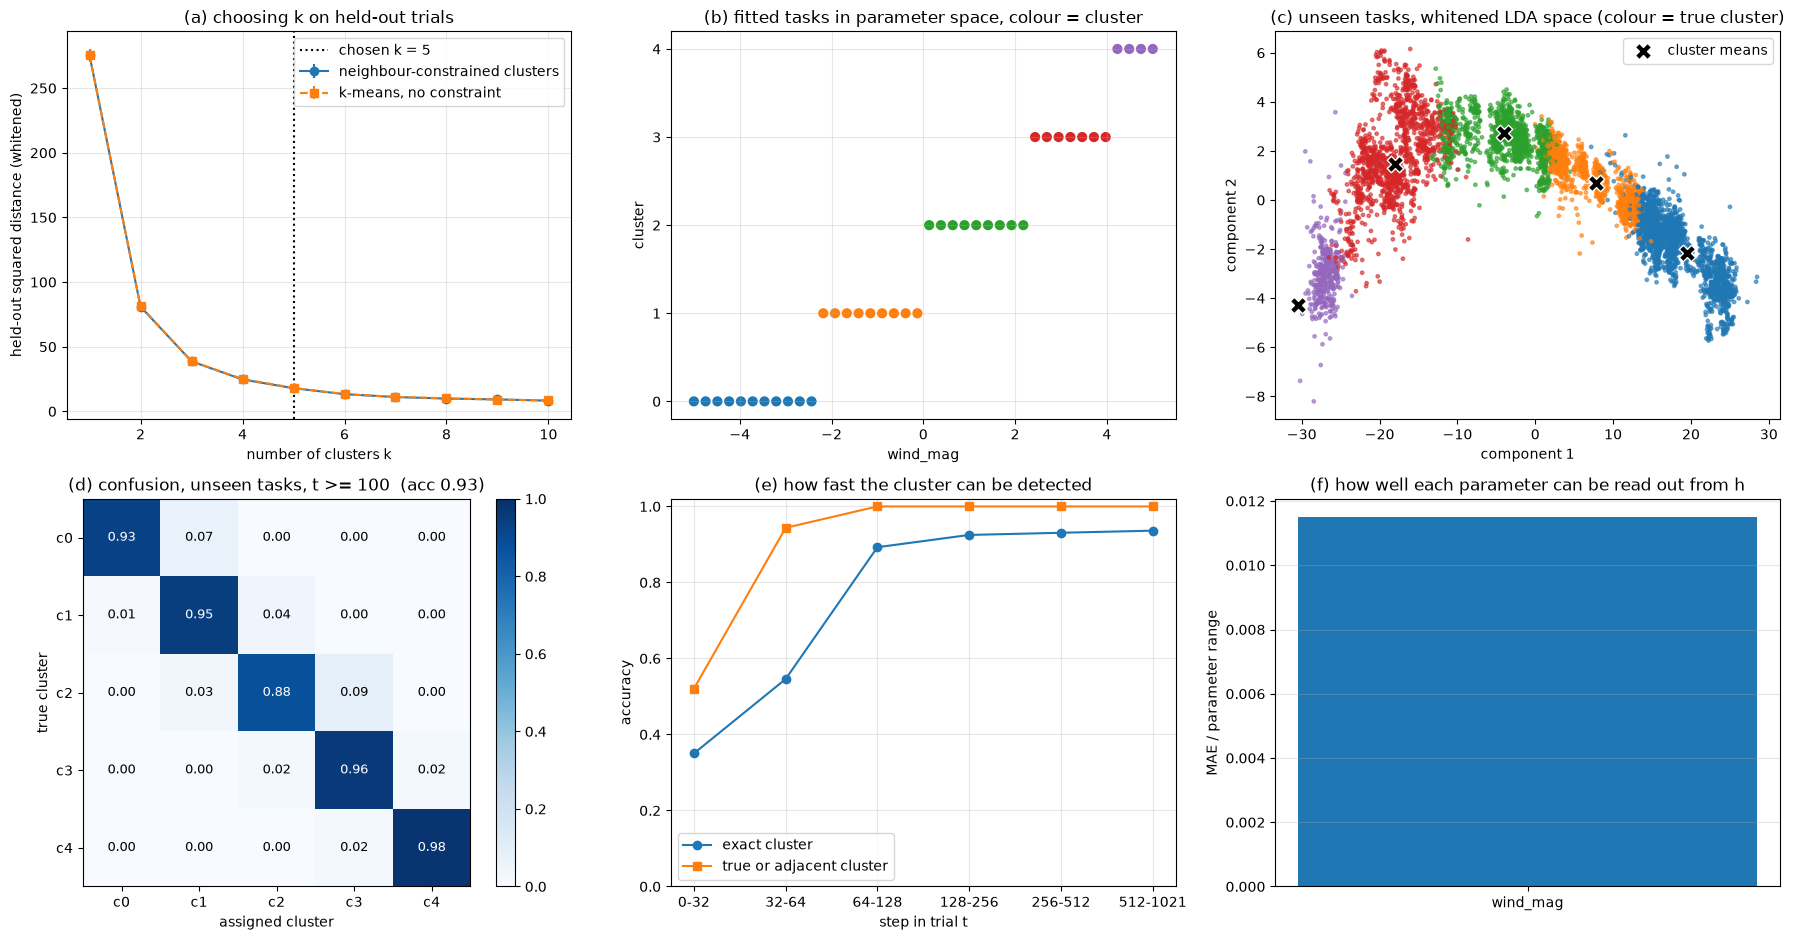

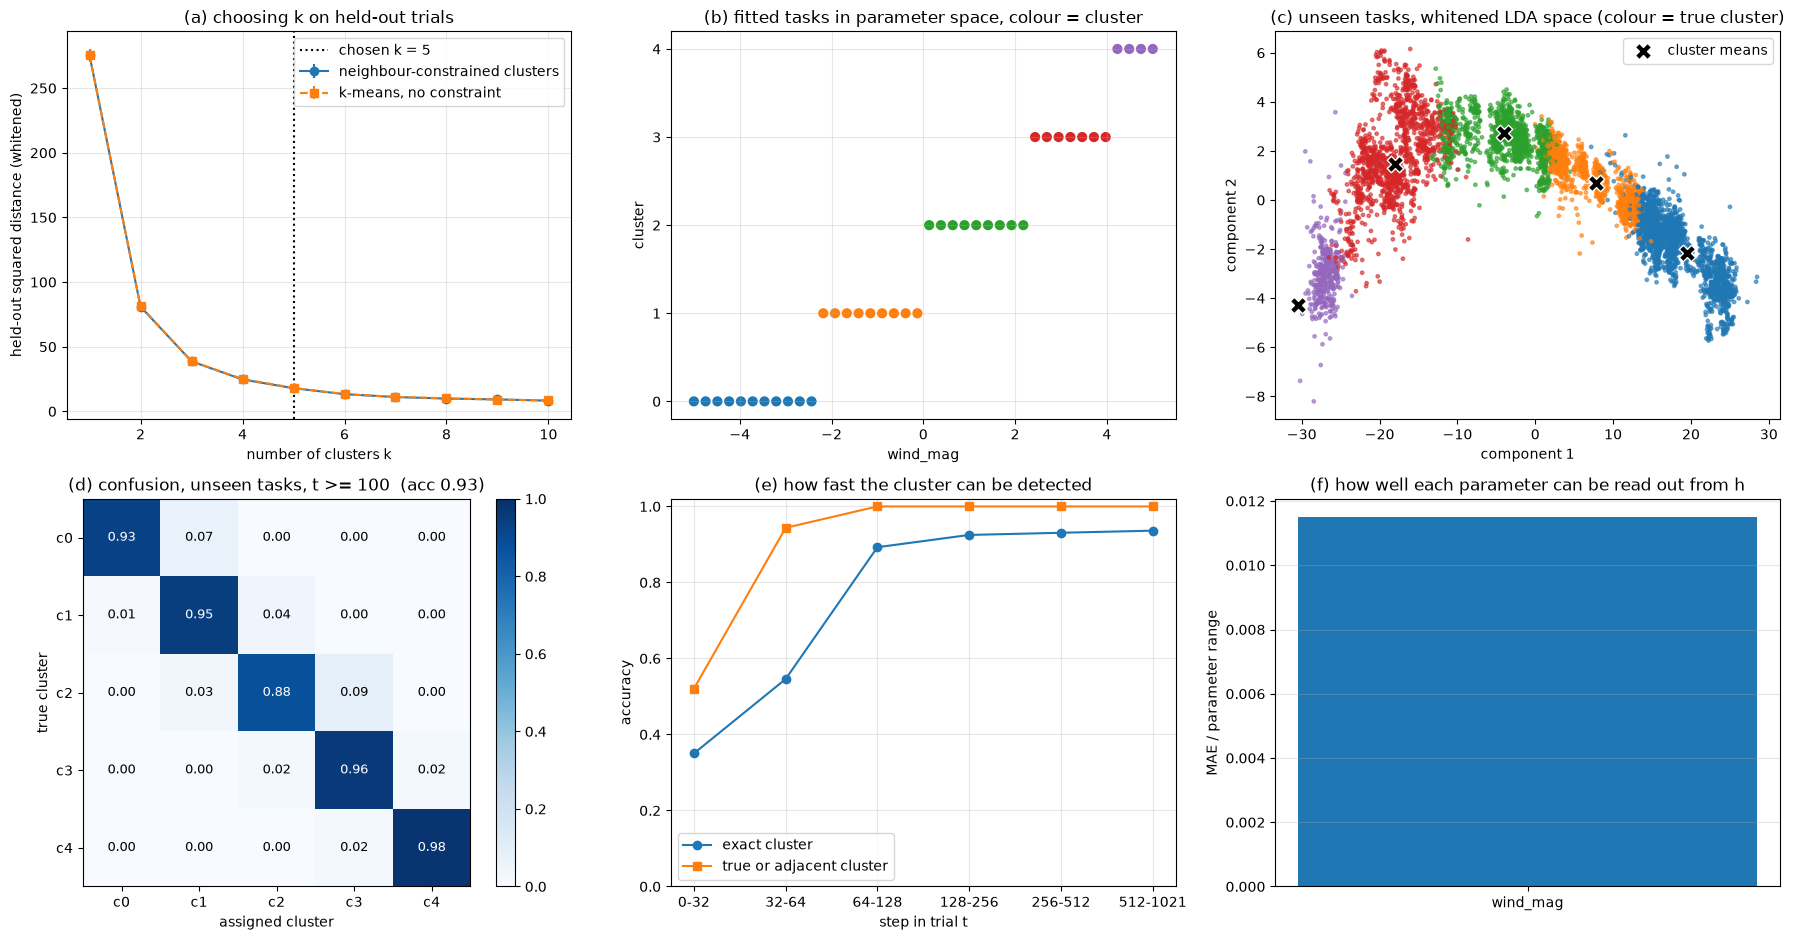

In [24]:
fig = make_figure(cm, cv, res, aux, test, keys, T0)
fig.savefig(os.path.join(OUT, "summary.png"), dpi=150)
fig